Loading data from AUP_ClinicalData_20260609.xlsx [AUP_ClinicalData_20260609.NO.DA]; HR+HER2- receptor source = Earliest_Met_Diagnosis ...
Loaded BAM stems: 784
Patients with BAM-matched barcoded blood draws but NOT plotted
Patients with BAM-matched barcoded blood draws: 262
Patients plotted in treatment-line matrix: 244
Missing patients: 18
--------------------------------------------------------------------------------
6
10
30
585-6
585-8
587-12
588-37
993-16
993-24
993-3
993-36
995-6
997-5
999-10
999-16
999-21
999-24
999-27
Saved missing-patient QC table: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/Plot/Treatment_line/bam_matched_blood_draws_not_plotted.Earliest_Met_Diagnosis.csv

Missing blood-draw rows:
patient_id liquid_sample_id  Days_From_Primary_Diagnosis   Category Met_Therapy_Line
        10         AN3U-NB1                         1988 Blood_Draw              NaN
        30         APK5-NB1                         2044 Blood_Draw              NaN
     

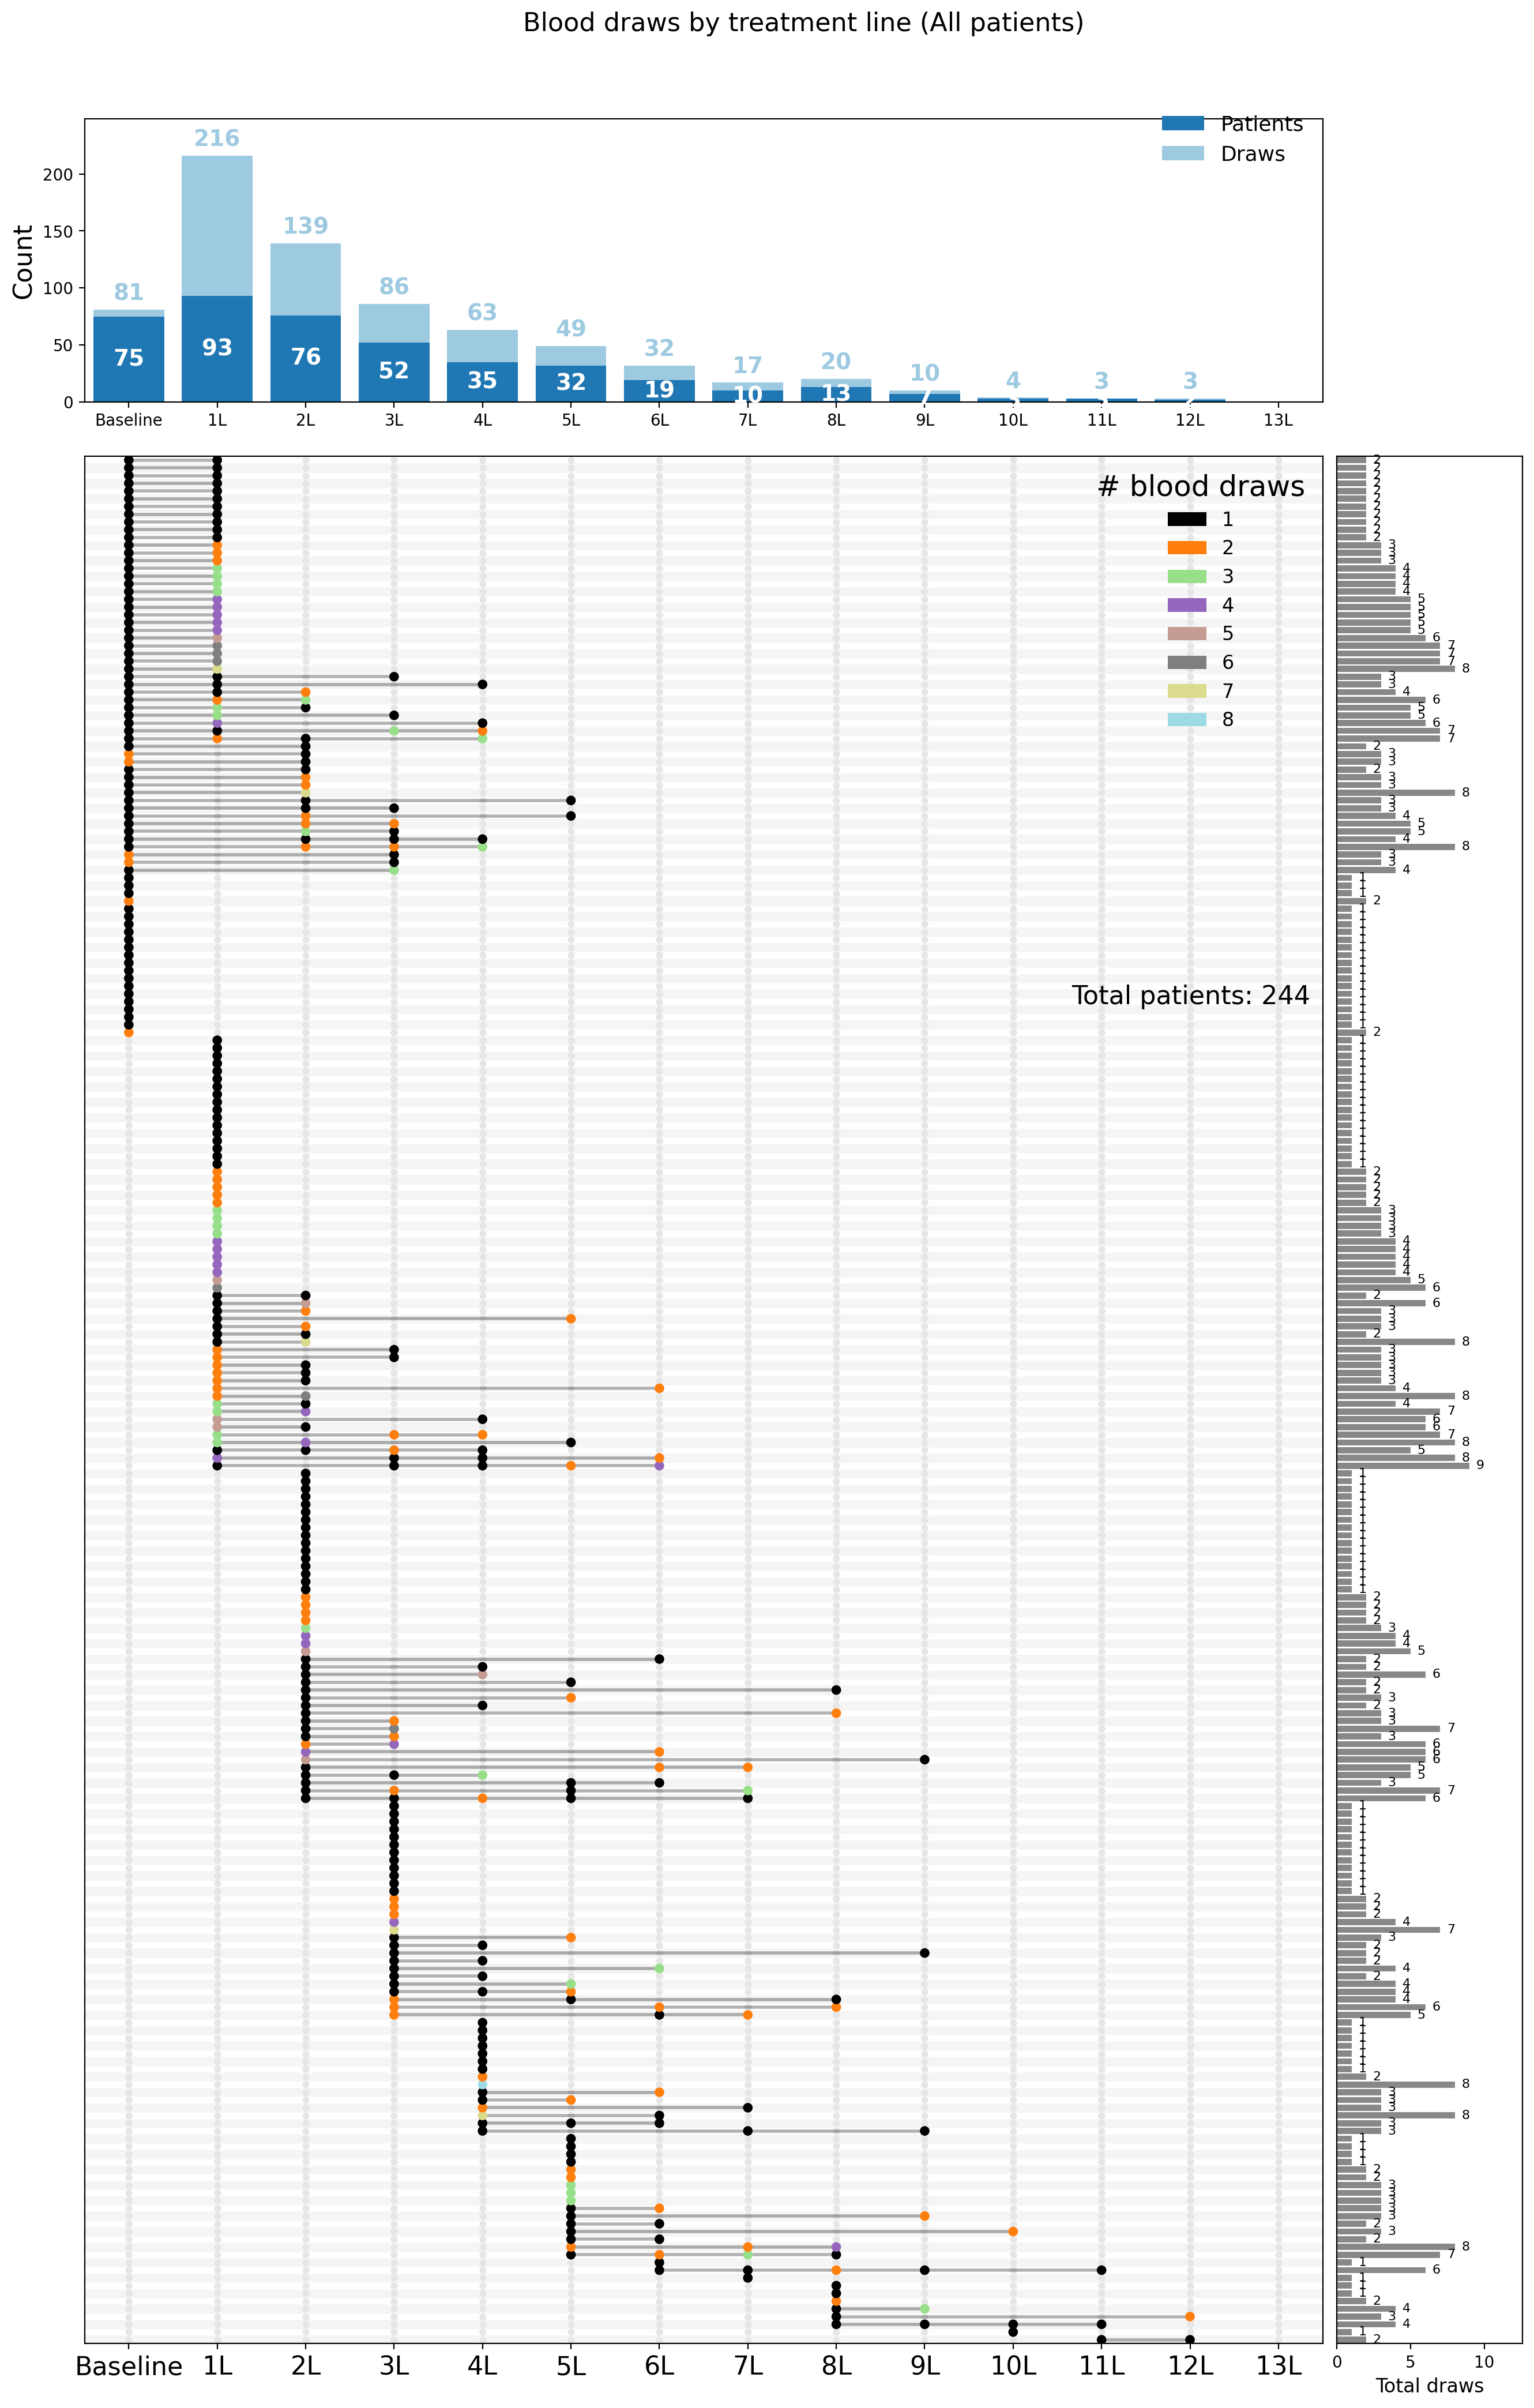

[OK] All-patient matrix: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/Plot/Treatment_line/all_patients_matrix.Earliest_Met_Diagnosis.png
[OK] All-patient summary: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/Plot/Treatment_line/all_patients_summary.Earliest_Met_Diagnosis.txt

========== HR+HER2- patient definition ==========
Receptor source setting: Earliest_Met_Diagnosis
Source rows: earliest classifiable Category == 'Met_Diagnosis' row by Days_From_Primary_Diagnosis
Rule: (ER positive OR PR positive) AND HER2 negative
Source rows before patient-level selection: 1060
Unique patients with selected receptor source: 250
HR+HER2- patients from Earliest_Met_Diagnosis: 169

Subtype distribution from selected receptor source:
HR+HER2-    169
HR-HER2-     55
HR+HER2+     20
HR-HER2+      6
Name: group, dtype: int64


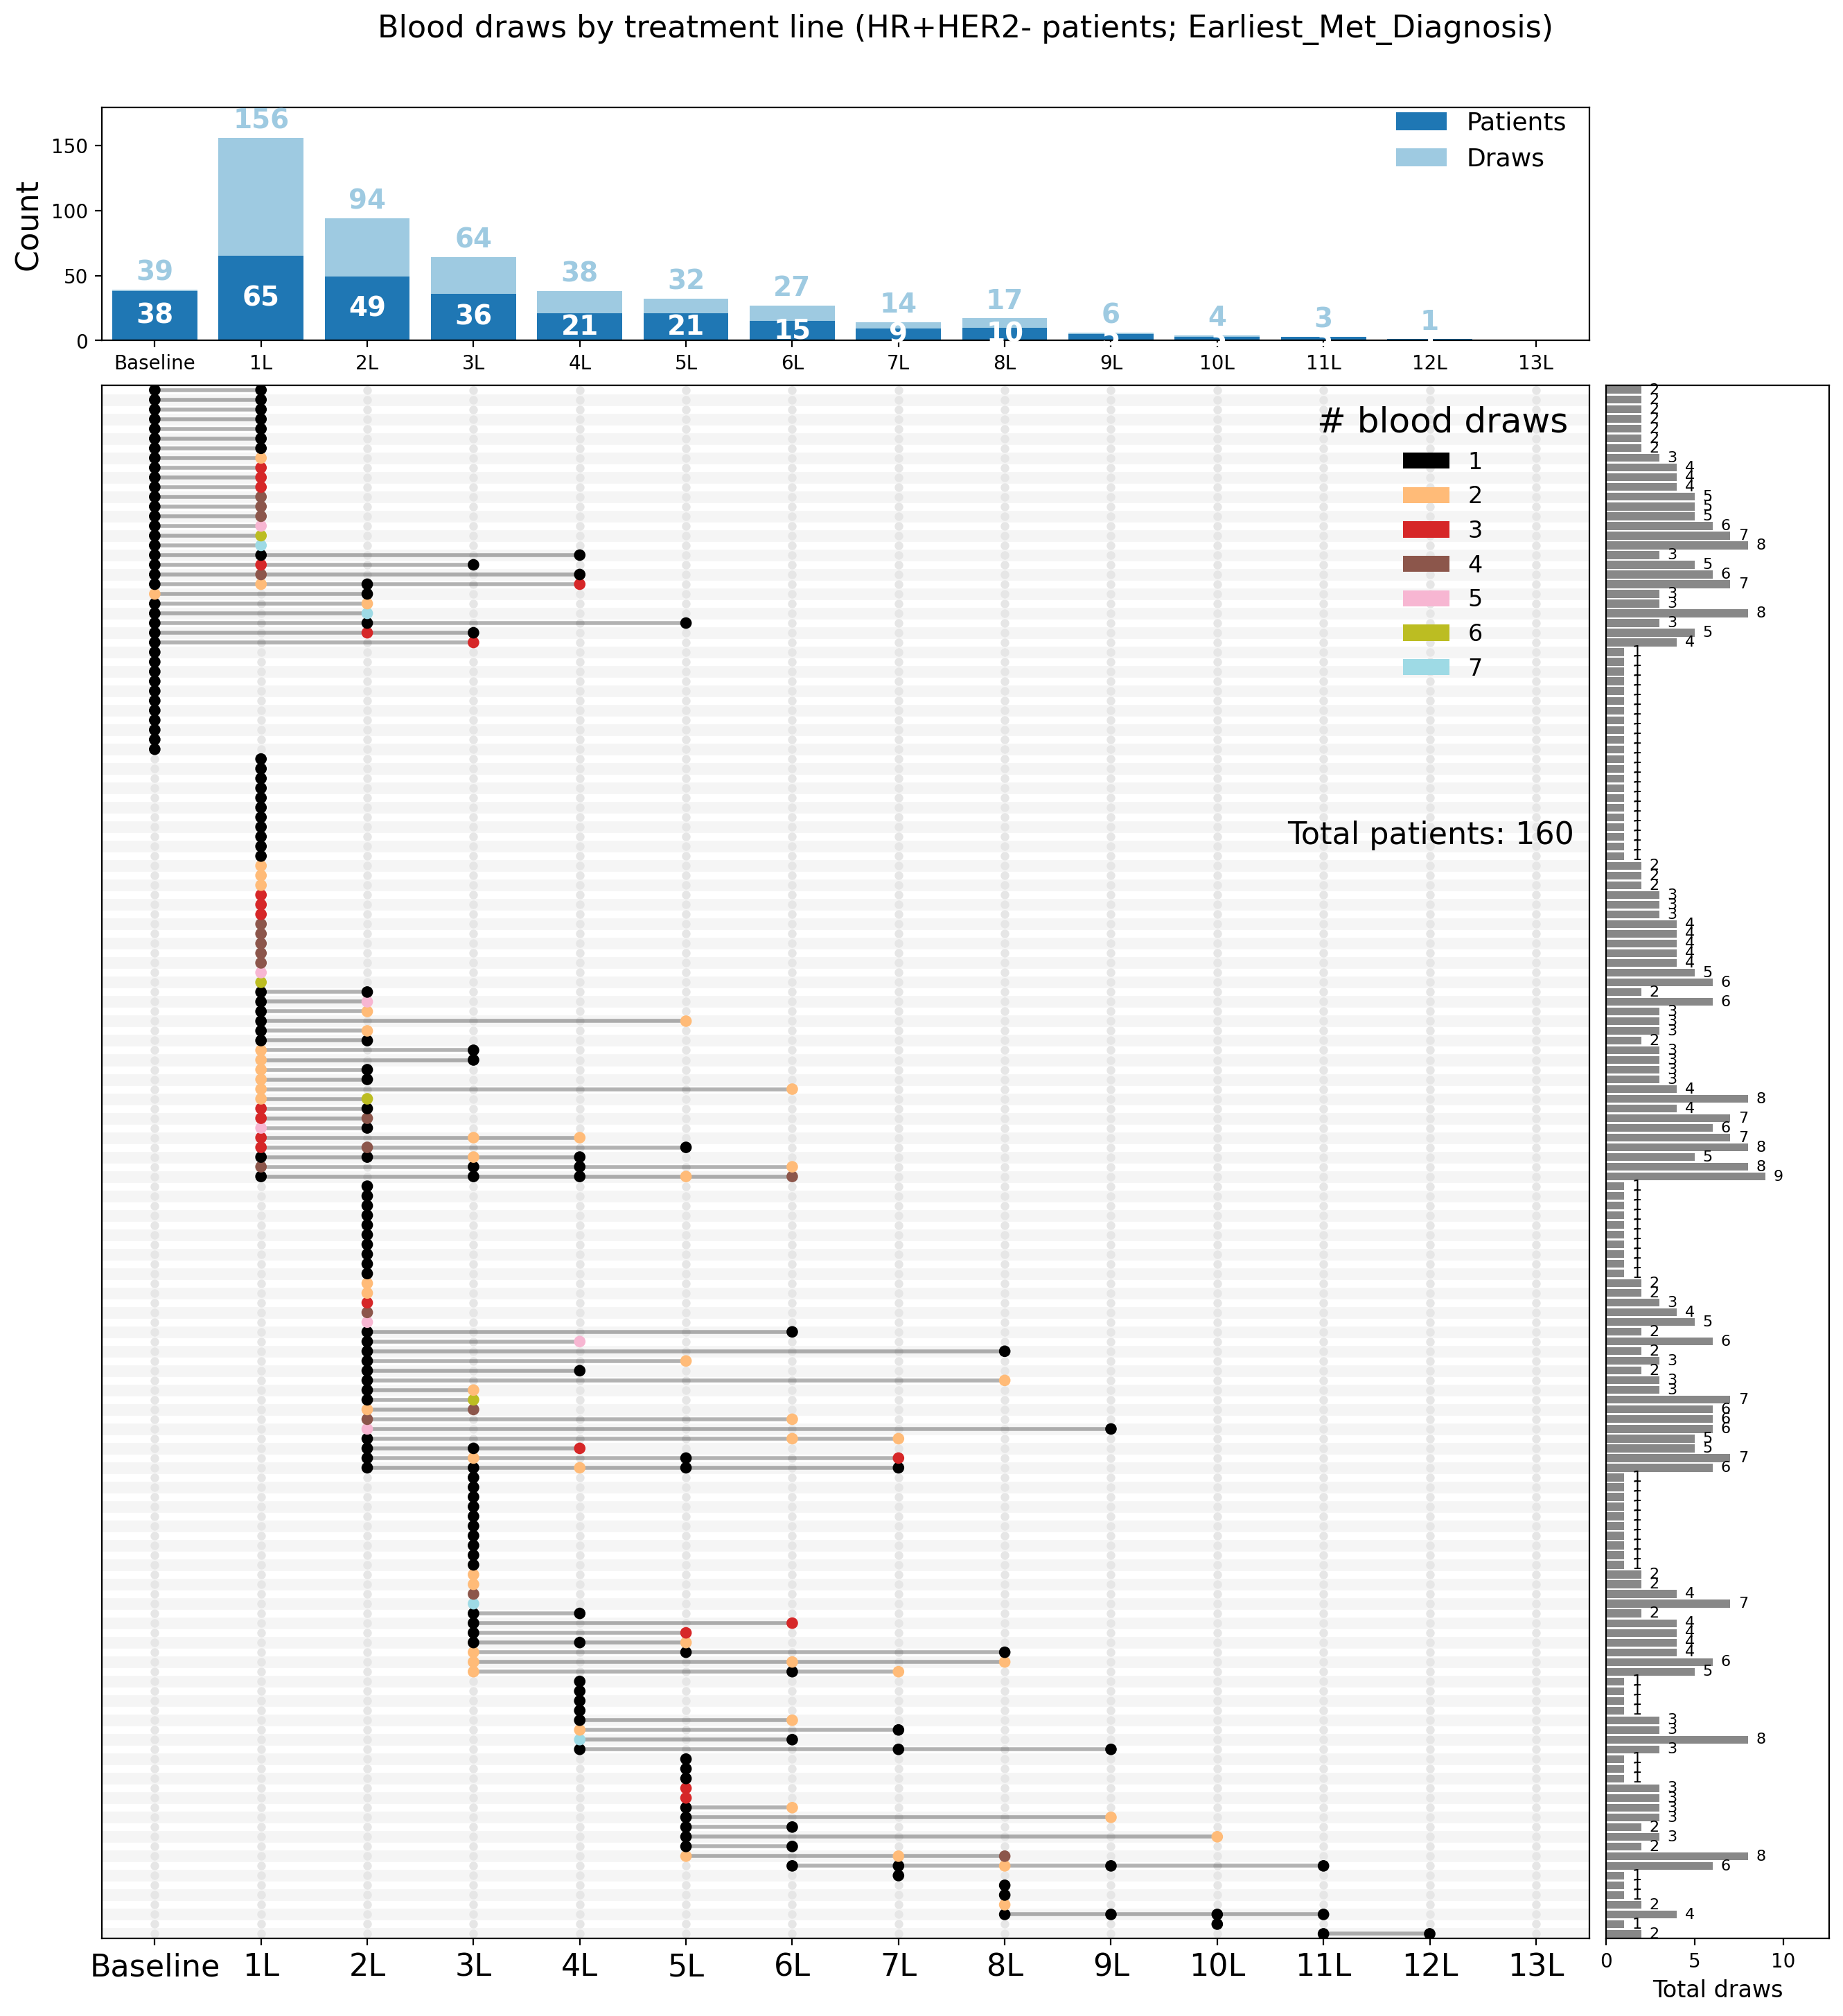

[OK] HR+HER2- matrix: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/Plot/Treatment_line/hrpos_her2neg_matrix.Earliest_Met_Diagnosis.png
[OK] HR+HER2- summary: /ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data/Plot/Treatment_line/hrpos_her2neg_summary.Earliest_Met_Diagnosis.txt

DONE


In [5]:
"""
Treatment-line vs blood-draw matrix for AURORA clinical data.

Inputs:
- AUP_ClinicalData_20260609.xlsx
  Sheet: AUP_ClinicalData_20260609.NO.DA

Blood-draw matching:
- Blood draws use Barcode as the liquid biopsy ID, e.g. AMCZ-NB1.
- The script also supports collaborator_sample_id for older files.
- A blood draw is retained only if its liquid biopsy ID matches a BAM stem
  in the BAM directory.

Treatment-line assignment:
- Treatment-line start days are taken from rows where Category contains
  Met_*Therapy and where both Met_Therapy_Line and
  Days_From_Primary_Diagnosis are available.
- Blood draws before first-line therapy are labeled Baseline.
- Blood draws after a given line start and before the next line start are
  assigned to that line.

HR+HER2- subset definition:
- Receptor source is controlled by RECEPTOR_SOURCE.

Options:
  "First_Primary"
      - Uses rows where Category == "First_Primary".
      - Receptor status is collapsed per patient.

  "Earliest_Met_Diagnosis"
      - Uses rows where Category == "Met_Diagnosis".
      - For patients with multiple Met_Diagnosis rows, the script selects
        the earliest row with classifiable ER/PR/HER2 information using
        Days_From_Primary_Diagnosis.

HR+HER2- is defined as:
    ER positive OR PR positive
    AND HER2 negative.

Outputs:
- all_patients_matrix.<RECEPTOR_SOURCE>.png / .txt
- hrpos_her2neg_matrix.<RECEPTOR_SOURCE>.png / .txt
"""

from __future__ import annotations

from collections import defaultdict
from datetime import datetime
from pathlib import Path
from typing import Dict, List, Tuple

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.patches import Patch
import numpy as np
import pandas as pd


# ============================================================
# Paths
# ============================================================

BASE_DIR = Path(
    "/ix1/alee/LO_LAB/Personal/Rahul/cfDNA_project/AURORA/Clinical_data"
)

CLINICAL_XLSX = BASE_DIR / "AUP_ClinicalData_20260609.xlsx"
CLINICAL_SHEET = "AUP_ClinicalData_20260609.NO.DA"

BAM_DIR = Path(
    "/ix1/alee/LO_LAB/General/Lab_Data/20260324_Broad_ULPWGS_TBCRC_AURORA_Rahul/bam_file"
)


# ============================================================
# Receptor source setting for HR+HER2- subset
# ============================================================
# Options:
#   "First_Primary"
#   "Earliest_Met_Diagnosis"
# ============================================================

# RECEPTOR_SOURCE = "First_Primary"
RECEPTOR_SOURCE = "Earliest_Met_Diagnosis"


# ============================================================
# Output directory and files
# ============================================================

OUT_DIR = BASE_DIR / "Plot/Treatment_line"
OUT_DIR.mkdir(parents=True, exist_ok=True)

ALL_MATRIX_PNG = OUT_DIR / f"all_patients_matrix.{RECEPTOR_SOURCE}.png"
ALL_SUMMARY_TXT = OUT_DIR / f"all_patients_summary.{RECEPTOR_SOURCE}.txt"

HR_MATRIX_PNG = OUT_DIR / f"hrpos_her2neg_matrix.{RECEPTOR_SOURCE}.png"
HR_SUMMARY_TXT = OUT_DIR / f"hrpos_her2neg_summary.{RECEPTOR_SOURCE}.txt"

MISSING_PATIENTS_CSV = OUT_DIR / f"bam_matched_blood_draws_not_plotted.{RECEPTOR_SOURCE}.csv"


# ============================================================
# Treatment line parsing
# ============================================================

LINE_TEXT_MAP = {
    "first": 1,
    "second": 2,
    "third": 3,
    "fourth": 4,
    "fifth": 5,
    "sixth": 6,
    "seventh": 7,
    "eighth": 8,
    "ninth": 9,
    "tenth": 10,
    "eleventh": 11,
    "twelfth": 12,
    "thirteenth": 13,
}


def normalize_status(x: object) -> str:
    """
    Normalize receptor status to Positive / Negative / Unknown.
    """

    if pd.isna(x):
        return "Unknown"

    v = str(x).strip().lower()

    if v in {"positive", "pos", "+", "1", "yes"}:
        return "Positive"

    if v in {"negative", "neg", "-", "0", "no"}:
        return "Negative"

    if "positive" in v:
        return "Positive"

    if "negative" in v:
        return "Negative"

    return "Unknown"


def choose_representative_status(series: pd.Series) -> str:
    """
    Collapse repeated receptor values for one patient.

    Unknown values are ignored.
    If multiple known values exist, the most frequent known value is used.
    """

    vals = series.map(normalize_status)
    vals = vals[vals != "Unknown"]

    if vals.empty:
        return "Unknown"

    return str(vals.value_counts().index[0])


def derive_hr_her2_group(er: str, pr: str, her2: str) -> str:
    """
    Derive receptor group from ER, PR, and HER2.

    HR+:
        ER Positive OR PR Positive

    HR-:
        ER Negative AND PR Negative

    HER2 group:
        based on HER2_Status
    """

    er_n = normalize_status(er)
    pr_n = normalize_status(pr)
    her2_n = normalize_status(her2)

    if her2_n == "Unknown":
        return "Unknown"

    hr_pos = (er_n == "Positive") or (pr_n == "Positive")
    hr_neg = (er_n == "Negative") and (pr_n == "Negative")

    if hr_pos and her2_n == "Negative":
        return "HR+HER2-"

    if hr_pos and her2_n == "Positive":
        return "HR+HER2+"

    if hr_neg and her2_n == "Negative":
        return "HR-HER2-"

    if hr_neg and her2_n == "Positive":
        return "HR-HER2+"

    return "Unknown"


def parse_line_number(x: object) -> int | None:
    """
    Parse metastatic therapy line.

    Examples:
        first -> 1
        second -> 2
        1 -> 1
        2.0 -> 2
    """

    if pd.isna(x):
        return None

    s = str(x).strip().lower()

    if not s:
        return None

    if s in LINE_TEXT_MAP:
        return LINE_TEXT_MAP[s]

    try:
        return int(float(s))
    except ValueError:
        return None


def ordinal_label(n: int) -> str:
    if n == 0:
        return "Baseline"

    if 10 <= (n % 100) <= 20:
        suffix = "th"
    else:
        suffix = {1: "st", 2: "nd", 3: "rd"}.get(n % 10, "th")

    return f"{n}{suffix} line"


def compact_line_label(n: int) -> str:
    return "Baseline" if n == 0 else f"{n}L"


def liquid_sample_id(row: pd.Series) -> str | None:
    """
    Liquid biopsy ID for BAM matching:
        Barcode in newer files
        collaborator_sample_id in older files
    """

    for col in ("Barcode", "collaborator_sample_id"):
        if col not in row.index:
            continue

        v = row[col]

        if pd.isna(v):
            continue

        s = str(v).strip()

        if s and s.lower() != "nan":
            return s

    return None


def sort_patient_id(pid: str):
    """
    Sort patient IDs numerically when possible.
    Keeps IDs like 588-1 as strings.
    """

    s = str(pid)

    try:
        return (0, float(s))
    except ValueError:
        return (1, s)


# ============================================================
# Data loading
# ============================================================

def load_clinical_data(clinical_xlsx: Path, sheet_name: str) -> pd.DataFrame:
    """
    Load clinical Excel file and add helper columns.
    """

    df = pd.read_excel(clinical_xlsx, sheet_name=sheet_name)

    required_cols = [
        "patient_id",
        "Category",
        "Days_From_Primary_Diagnosis",
        "Met_Therapy_Line",
        "ER_Status",
        "PR_Status",
        "HER2_Status",
    ]

    for col in required_cols:
        if col not in df.columns:
            raise ValueError(f"Missing required column in clinical file: {col}")

    df["patient_id"] = df["patient_id"].astype("string").str.strip()
    df["Category"] = df["Category"].astype("string").str.strip()

    df["Days_From_Primary_Diagnosis"] = pd.to_numeric(
        df["Days_From_Primary_Diagnosis"],
        errors="coerce",
    )

    df["line_num"] = df["Met_Therapy_Line"].map(parse_line_number)
    df["liquid_sample_id"] = df.apply(liquid_sample_id, axis=1)

    return df


def load_bam_stems(bam_dir: Path) -> set[str]:
    """
    Load BAM stems from BAM directory.
    Example:
        AMCZ-NB1.bam -> AMCZ-NB1
    """

    stems: set[str] = set()

    if not bam_dir.is_dir():
        print(f"WARNING: BAM directory does not exist: {bam_dir}")
        return stems

    for p in bam_dir.iterdir():
        if p.is_file() and p.suffix.lower() == ".bam":
            stems.add(p.stem)

    return stems


# ============================================================
# HR+HER2- patient subset
# ============================================================

def load_hrpos_her2neg_patients(
    clinical_df: pd.DataFrame,
    receptor_source: str = RECEPTOR_SOURCE,
) -> set[str]:
    """
    Define HR+HER2- patients using selected receptor source.

    Options:
      First_Primary:
        - Use Category == "First_Primary"
        - Collapse receptor status per patient

      Earliest_Met_Diagnosis:
        - Use Category == "Met_Diagnosis"
        - Select earliest classifiable Met_Diagnosis row per patient
          using Days_From_Primary_Diagnosis

    HR+HER2- definition:
      - HR positive = ER positive OR PR positive
      - HER2 negative = HER2_Status negative
    """

    receptor_source = str(receptor_source).strip()

    if receptor_source not in {"First_Primary", "Earliest_Met_Diagnosis"}:
        raise ValueError(
            "RECEPTOR_SOURCE must be either 'First_Primary' "
            "or 'Earliest_Met_Diagnosis'"
        )

    df = clinical_df.copy()

    df["Category_clean"] = (
        df["Category"]
        .astype("string")
        .str.strip()
        .str.lower()
    )

    df["patient_id"] = df["patient_id"].astype("string").str.strip()

    df = df[
        df["patient_id"].notna()
        & df["patient_id"].ne("")
        & df["patient_id"].str.lower().ne("nan")
        & df["patient_id"].str.lower().ne("none")
    ].copy()

    # ============================================================
    # Option 1: First_Primary receptor source
    # ============================================================

    if receptor_source == "First_Primary":

        source_rows = df[
            df["Category_clean"] == "first_primary"
        ].copy()

        receptor = source_rows[
            [
                "patient_id",
                "ER_Status",
                "PR_Status",
                "HER2_Status",
            ]
        ].copy()

        receptor = (
            receptor
            .groupby("patient_id", as_index=False)
            .agg(
                ER_Status=("ER_Status", choose_representative_status),
                PR_Status=("PR_Status", choose_representative_status),
                HER2_Status=("HER2_Status", choose_representative_status),
            )
        )

        receptor["group"] = receptor.apply(
            lambda r: derive_hr_her2_group(
                r["ER_Status"],
                r["PR_Status"],
                r["HER2_Status"],
            ),
            axis=1,
        )

        source_label = "Category == 'First_Primary'"

    # ============================================================
    # Option 2: Earliest Met_Diagnosis receptor source
    # ============================================================

    else:

        source_rows = df[
            df["Category_clean"] == "met_diagnosis"
        ].copy()

        receptor = source_rows[
            [
                "patient_id",
                "Days_From_Primary_Diagnosis",
                "ER_Status",
                "PR_Status",
                "HER2_Status",
            ]
        ].copy()

        receptor["Days_From_Primary_Diagnosis"] = pd.to_numeric(
            receptor["Days_From_Primary_Diagnosis"],
            errors="coerce",
        )

        receptor["ER_Status_norm"] = receptor["ER_Status"].map(normalize_status)
        receptor["PR_Status_norm"] = receptor["PR_Status"].map(normalize_status)
        receptor["HER2_Status_norm"] = receptor["HER2_Status"].map(normalize_status)

        receptor["group"] = receptor.apply(
            lambda r: derive_hr_her2_group(
                r["ER_Status_norm"],
                r["PR_Status_norm"],
                r["HER2_Status_norm"],
            ),
            axis=1,
        )

        # Keep only classifiable metastatic receptor rows
        receptor = receptor[
            receptor["group"] != "Unknown"
        ].copy()

        # Select earliest classifiable Met_Diagnosis row per patient
        receptor = receptor.sort_values(
            by=["patient_id", "Days_From_Primary_Diagnosis"],
            ascending=[True, True],
            na_position="last",
        )

        receptor = receptor.drop_duplicates(
            subset=["patient_id"],
            keep="first",
        ).copy()

        receptor["ER_Status"] = receptor["ER_Status_norm"]
        receptor["PR_Status"] = receptor["PR_Status_norm"]
        receptor["HER2_Status"] = receptor["HER2_Status_norm"]

        source_label = (
            "earliest classifiable Category == 'Met_Diagnosis' row "
            "by Days_From_Primary_Diagnosis"
        )

    # ============================================================
    # Select HR+HER2- patients
    # ============================================================

    hr_ids = set(
        receptor.loc[
            receptor["group"] == "HR+HER2-",
            "patient_id",
        ].astype(str).tolist()
    )

    print("\n========== HR+HER2- patient definition ==========")
    print(f"Receptor source setting: {receptor_source}")
    print(f"Source rows: {source_label}")
    print("Rule: (ER positive OR PR positive) AND HER2 negative")
    print(f"Source rows before patient-level selection: {source_rows.shape[0]}")
    print(f"Unique patients with selected receptor source: {receptor['patient_id'].nunique()}")
    print(f"HR+HER2- patients from {receptor_source}: {len(hr_ids)}")

    print("\nSubtype distribution from selected receptor source:")
    print(receptor["group"].value_counts(dropna=False))

    return hr_ids


# ============================================================
# Treatment-line assignment
# ============================================================

def infer_treatment_line(
    blood_day: float,
    treatment_starts: Dict[int, float],
) -> int:
    """
    Assign a blood draw to treatment line based on blood draw day.

    Return:
        -1 = cannot infer
         0 = baseline, before first-line therapy
         1+ = treatment line
    """

    if not treatment_starts:
        return -1

    sorted_lines = sorted(treatment_starts.items(), key=lambda kv: kv[0])

    first_line, first_day = sorted_lines[0]

    if blood_day < first_day:
        return 0

    for i, (line_num, start_day) in enumerate(sorted_lines):

        if i == len(sorted_lines) - 1:
            return line_num

        next_line, next_start = sorted_lines[i + 1]

        if start_day <= blood_day < next_start:
            return line_num

    return sorted_lines[-1][0]


def load_blood_draw_line_counts(
    df: pd.DataFrame,
    bam_stems: set[str],
    patient_filter: set[str] | None = None,
) -> Tuple[List[Tuple[str, List[str]]], Dict[str, Dict[int, int]], int, Dict]:
    """
    Count blood draws per patient per inferred treatment line.

    If patient_filter is provided, only those patients are included.
    """

    df = df.copy()
    df["patient_id"] = df["patient_id"].astype(str).str.strip()

    if patient_filter is not None:
        patient_filter = set(str(x).strip() for x in patient_filter)
        df = df[df["patient_id"].isin(patient_filter)].copy()

    # ------------------------------------------------------------
    # Treatment start days per patient/line
    # ------------------------------------------------------------

    therapy_rows = df[
        df["line_num"].notna()
        & df["Days_From_Primary_Diagnosis"].notna()
        & df["Category"].astype(str).str.contains(
            "Met_.*Therapy",
            regex=True,
            na=False,
        )
    ].copy()

    treatment_starts: Dict[str, Dict[int, float]] = defaultdict(dict)

    for (pid, line), grp in therapy_rows.groupby(["patient_id", "line_num"]):
        treatment_starts[str(pid)][int(line)] = float(
            grp["Days_From_Primary_Diagnosis"].min()
        )

    # ------------------------------------------------------------
    # Blood draw rows with BAM-matched liquid IDs
    # ------------------------------------------------------------

    blood_rows = df[
        (df["Category"].astype(str).str.strip() == "Blood_Draw")
        & df["Days_From_Primary_Diagnosis"].notna()
        & df["liquid_sample_id"].notna()
    ].copy()

    blood_rows["liquid_sample_id"] = (
        blood_rows["liquid_sample_id"]
        .astype(str)
        .str.strip()
    )

    blood_rows = blood_rows[
        blood_rows["liquid_sample_id"].isin(bam_stems)
    ].copy()

    patient_to_line_counts: Dict[str, Dict[int, int]] = defaultdict(
        lambda: defaultdict(int)
    )

    inferred = 0
    failed = 0
    max_line = 0

    for _, r in blood_rows.iterrows():

        pid = str(r["patient_id"]).strip()
        blood_day = float(r["Days_From_Primary_Diagnosis"])

        line = infer_treatment_line(
            blood_day,
            treatment_starts.get(pid, {}),
        )

        if line < 0:
            failed += 1
            continue

        patient_to_line_counts[pid][line] += 1
        inferred += 1
        max_line = max(max_line, line)

    max_line_defined = max(
        (max(v.keys()) for v in treatment_starts.values() if v),
        default=0,
    )

    max_line = max(max_line, max_line_defined)

    cohort: List[Tuple[str, List[str]]] = [
        (pid, [pid])
        for pid in sorted(patient_to_line_counts.keys(), key=sort_patient_id)
    ]

    stats = {
        "inferred": inferred,
        "failed": failed,
        "with_blood_draws": len(patient_to_line_counts),
        "input_patients": df["patient_id"].nunique(),
        "patients_with_any_blood_draw_rows": df.loc[
            df["Category"].astype(str).str.strip() == "Blood_Draw",
            "patient_id",
        ].nunique(),
        "patients_with_blood_draw_liquid_id": df.loc[
            (df["Category"].astype(str).str.strip() == "Blood_Draw")
            & df["liquid_sample_id"].notna(),
            "patient_id",
        ].nunique(),
    }

    return cohort, patient_to_line_counts, max_line, stats


# ============================================================
# Matrix building
# ============================================================

def build_matrix(
    cohort: List[Tuple[str, List[str]]],
    patient_to_line_counts: Dict[str, Dict[int, int]],
    lines: List[int],
) -> Tuple[np.ndarray, List[str]]:

    num_patients = len(cohort)

    mat = np.zeros(
        (len(lines), num_patients),
        dtype=int,
    )

    labels: List[str] = []
    line_to_idx = {line: i for i, line in enumerate(lines)}

    for col, (pid, _) in enumerate(cohort):

        labels.append(pid)

        for line, cnt in patient_to_line_counts.get(pid, {}).items():

            if line in line_to_idx:
                mat[line_to_idx[line], col] = int(cnt)

    return mat, labels


def write_summary(
    mat: np.ndarray,
    patient_ids: List[str],
    lines: List[int],
    stats: Dict,
    out_path: Path,
    title: str,
    source_label: str,
) -> None:

    per_line_patients = (mat > 0).sum(axis=1).astype(int)
    per_line_draws = mat.sum(axis=1).astype(int)

    with out_path.open("w", encoding="utf-8") as f:

        f.write("=" * 70 + "\n")
        f.write(title + "\n")
        f.write("=" * 70 + "\n")
        f.write(f"Generated: {datetime.now().strftime('%Y-%m-%d %H:%M:%S')}\n")
        f.write(f"Source: {source_label}\n")
        f.write(f"Receptor source setting: {RECEPTOR_SOURCE}\n\n")

        f.write(f"Input patients considered: {stats['input_patients']}\n")
        f.write("Filter: BAM-matched liquid sample ID, Barcode/BAM stem only\n")
        f.write(f"Patients with any Blood_Draw rows: {stats['patients_with_any_blood_draw_rows']}\n")
        f.write(f"Patients with Blood_Draw liquid sample ID: {stats['patients_with_blood_draw_liquid_id']}\n")
        f.write(f"Patients with blood draws visualized: {stats['with_blood_draws']}\n")
        f.write(f"Blood draws assigned to treatment line: {stats['inferred']}\n")
        f.write(f"Blood draws dropped, no treatment line info: {stats['failed']}\n")
        f.write(f"Treatment line range: {ordinal_label(0)} to {ordinal_label(max(lines))}\n\n")

        f.write(f"{'Line':<12} {'Patients':<12} {'Total Draws':<15}\n")
        f.write("-" * 70 + "\n")

        for i, line in enumerate(lines):
            label = compact_line_label(line)
            f.write(
                f"{label:<12} "
                f"{per_line_patients[i]:<12} "
                f"{per_line_draws[i]:<15}\n"
            )


# ============================================================
# Plotting
# ============================================================

def plot_matrix(
    mat: np.ndarray,
    col_labels: List[str],
    lines: List[int],
    out_png: Path,
    title: str,
) -> None:

    mat_t = mat.T
    labels = np.array(col_labels)

    rows, cols = mat_t.shape

    if rows == 0:
        print(f"WARNING: No patients to plot for: {title}")
        return

    # ------------------------------------------------------------
    # Order patients by baseline presence then proximity to earlier lines
    # ------------------------------------------------------------

    order_keys = []

    for y in range(rows):

        row = mat_t[y, :]
        nz = np.where(row > 0)[0]
        has_baseline = row[0] > 0 if cols > 0 else False

        if nz.size == 0:
            gap = cols + 20
            total_lines = 0
            draws_at_nearest = 0

        else:
            total_lines = nz.size

            if has_baseline:
                nz_after = nz[nz > 0]

                if nz_after.size > 0:
                    nearest = int(nz_after[0])
                    gap = nearest
                    draws_at_nearest = int(row[nearest])
                else:
                    gap = cols + 10
                    draws_at_nearest = 0

            else:
                nearest = int(nz[0])
                gap = cols + 10 + nearest
                draws_at_nearest = int(row[nearest])

        order_keys.append(
            (
                y,
                (
                    not has_baseline,
                    gap,
                    total_lines,
                    draws_at_nearest,
                    y,
                ),
            )
        )

    order = np.array(
        [idx for idx, _ in sorted(order_keys, key=lambda t: t[1])],
        dtype=int,
    )[::-1]

    mat_t = mat_t[order, :]
    labels = labels[order]

    per_line_patients = (mat > 0).sum(axis=1).astype(int)
    per_line_tests = mat.sum(axis=1).astype(int)
    patient_totals = mat_t.sum(axis=1).astype(int)

    # ------------------------------------------------------------
    # Figure size
    # ------------------------------------------------------------

    fig_h = max(12, rows * 0.035 * 2.52 + 2.0)
    fig_w = max(12, cols * 0.968)

    fig = plt.figure(figsize=(fig_w, fig_h), dpi=200)

    gs = GridSpec(
        2,
        2,
        width_ratios=[10, 1.5],
        height_ratios=[1.5, 10],
        hspace=0.05,
        wspace=0.02,
    )

    ax_top = fig.add_subplot(gs[0, 0])
    ax = fig.add_subplot(gs[1, 0], sharex=ax_top)
    ax_right = fig.add_subplot(gs[1, 1], sharey=ax)
    ax_top_right = fig.add_subplot(gs[0, 1])
    ax_top_right.axis("off")

    # ------------------------------------------------------------
    # Top bar plot
    # ------------------------------------------------------------

    x = np.arange(cols)

    dark = "#1f77b4"
    light = "#9ecae1"

    ax_top.bar(
        x,
        per_line_patients,
        width=0.8,
        color=dark,
        edgecolor="none",
        label="Patients",
        zorder=2,
    )

    residual = np.maximum(0, per_line_tests - per_line_patients)

    ax_top.bar(
        x,
        residual,
        bottom=per_line_patients,
        width=0.8,
        color=light,
        edgecolor="none",
        label="Draws",
        zorder=1,
    )

    ymax = max(int(per_line_tests.max()) if per_line_tests.size else 1, 1)

    ax_top.set_ylim(0, ymax * 1.15)
    ax_top.set_ylabel("Count", fontsize=16)
    ax_top.set_xticks([])
    ax_top.legend(
        loc="upper right",
        bbox_to_anchor=(1.0, 1.08),
        fontsize=13,
        frameon=False,
    )

    for i, (p, t) in enumerate(zip(per_line_patients, per_line_tests)):

        if p > 0:
            ax_top.text(
                i,
                p / 2.0,
                f"{p}",
                ha="center",
                va="center",
                fontsize=14,
                fontweight="bold",
                color="white",
            )

        if t > 0:
            ax_top.text(
                i,
                t + max(0.02 * ymax, 0.5),
                f"{t}",
                ha="center",
                va="bottom",
                fontsize=14,
                fontweight="bold",
                color=light,
            )

    # ------------------------------------------------------------
    # Matrix background
    # ------------------------------------------------------------

    for y in range(0, rows, 2):
        ax.axhspan(
            y - 0.5,
            y + 0.5,
            color="#f5f5f5",
            zorder=0,
        )

    yy, xx = np.meshgrid(
        np.arange(rows),
        np.arange(cols),
        indexing="ij",
    )

    ax.scatter(
        xx.flatten(),
        yy.flatten(),
        s=12,
        color="#e6e6e6",
        marker="o",
        zorder=1,
    )

    # ------------------------------------------------------------
    # Filled matrix points
    # ------------------------------------------------------------

    yy_idx, xx_idx = np.where(mat_t > 0)
    counts = mat_t[yy_idx, xx_idx]

    max_count = int(counts.max()) if counts.size > 0 else 1
    cmap = plt.cm.get_cmap("tab20", max_count if max_count > 0 else 1)

    count_to_color = {
        c: cmap((c - 1) % 20)
        for c in range(1, max_count + 1)
    }

    # Single blood-draw points as black for readability
    count_to_color[1] = (0.0, 0.0, 0.0, 1.0)

    ax.scatter(
        xx_idx,
        yy_idx,
        s=36,
        c=[count_to_color[int(c)] for c in counts],
        marker="o",
        zorder=3,
        edgecolors="none",
    )

    # Connect points for each patient
    for y in range(rows):
        xs = np.where(mat_t[y, :] > 0)[0]

        if xs.size >= 2:
            ax.plot(
                xs,
                [y] * len(xs),
                color="black",
                alpha=0.30,
                linewidth=2.0,
                zorder=2,
            )

    xticklabels = [compact_line_label(line) for line in lines]

    ax.set_xticks(np.arange(cols))
    ax.set_xticklabels(xticklabels, rotation=0, fontsize=16)
    ax.set_yticks([])
    ax.set_xlim(-0.5, cols - 0.5)
    ax.set_ylim(-0.5, rows - 0.5)

    fig.text(
        0.5,
        0.935,
        title,
        fontsize=16,
        ha="center",
        va="center",
    )

    ax.text(
        0.99,
        0.72,
        f"Total patients: {rows}",
        transform=ax.transAxes,
        ha="right",
        va="top",
        fontsize=16,
    )

    present_counts = sorted(
        {int(c) for c in counts}
    ) if counts.size > 0 else []

    handles = [
        Patch(
            facecolor=count_to_color[c],
            edgecolor="none",
            label=f"{c}",
        )
        for c in present_counts
    ]

    if handles:
        lg = ax.legend(
            handles=handles,
            title="# blood draws",
            loc="upper right",
            bbox_to_anchor=(1.0, 1.0),
            fontsize=12,
            frameon=False,
        )
        lg.get_title().set_fontsize(18)

    # ------------------------------------------------------------
    # Right-side total draws per patient
    # ------------------------------------------------------------

    ax_right.barh(
        np.arange(rows),
        patient_totals,
        color="#888888",
        edgecolor="none",
    )

    ax_right.set_ylim(-0.5, rows - 0.5)
    ax_right.set_yticks([])
    ax_right.set_xlabel("Total draws", fontsize=12)

    max_tot = int(patient_totals.max()) if patient_totals.size > 0 else 1

    ax_right.set_xlim(
        0,
        max_tot * 1.4 if max_tot > 0 else 1,
    )

    ax_right.tick_params(axis="x", labelsize=10)

    for y, total in enumerate(patient_totals):
        if total > 0:
            ax_right.text(
                total + max_tot * 0.05,
                y,
                f"{int(total)}",
                va="center",
                ha="left",
                fontsize=8,
            )

    fig.subplots_adjust(
        left=0.04,
        right=0.96,
        bottom=0.08,
        top=0.90,
        wspace=0.02,
        hspace=0.05,
    )

    fig.savefig(out_png, bbox_inches="tight")
    plt.show()
    plt.close(fig)


# ============================================================
# Run one matrix
# ============================================================

def run_one(
    cohort: List[Tuple[str, List[str]]],
    patient_to_line_counts: Dict[str, Dict[int, int]],
    max_line: int,
    stats: Dict,
    out_png: Path,
    out_txt: Path,
    title: str,
    source_label: str,
) -> None:

    lines = list(range(0, max_line + 1))

    mat, labels = build_matrix(
        cohort,
        patient_to_line_counts,
        lines,
    )

    write_summary(
        mat,
        labels,
        lines,
        stats,
        out_txt,
        title,
        source_label,
    )

    plot_matrix(
        mat,
        labels,
        lines,
        out_png,
        title,
    )


# ============================================================
# Main
# ============================================================

def main() -> None:

    source_label = (
        f"{CLINICAL_XLSX.name} [{CLINICAL_SHEET}]; "
        f"HR+HER2- receptor source = {RECEPTOR_SOURCE}"
    )

    print(f"Loading data from {source_label} ...")

    clinical_df = load_clinical_data(
        CLINICAL_XLSX,
        CLINICAL_SHEET,
    )

    bam_stems = load_bam_stems(BAM_DIR)

    print(f"Loaded BAM stems: {len(bam_stems)}")

    # ============================================================
    # All patients
    # ============================================================

    cohort_all, counts_all, max_all, stats_all = load_blood_draw_line_counts(
        clinical_df,
        bam_stems=bam_stems,
        patient_filter=None,
    )

    # ============================================================
    # QC: patients with BAM-matched barcoded blood draws but not plotted
    # ============================================================

    blood_barcode = clinical_df[
        (clinical_df["Category"].astype(str).str.strip() == "Blood_Draw")
        & clinical_df["patient_id"].notna()
        & clinical_df["Days_From_Primary_Diagnosis"].notna()
        & clinical_df["liquid_sample_id"].notna()
    ].copy()

    blood_barcode["patient_id"] = (
        blood_barcode["patient_id"]
        .astype(str)
        .str.strip()
    )

    blood_barcode["liquid_sample_id"] = (
        blood_barcode["liquid_sample_id"]
        .astype(str)
        .str.strip()
    )

    blood_barcode_bam = blood_barcode[
        blood_barcode["liquid_sample_id"].isin(bam_stems)
    ].copy()

    plotted_patient_ids = set(pid for pid, _ in cohort_all)
    barcode_bam_patient_ids = set(blood_barcode_bam["patient_id"])

    missing_patient_ids = sorted(
        barcode_bam_patient_ids - plotted_patient_ids,
        key=sort_patient_id,
    )

    print("=" * 80)
    print("Patients with BAM-matched barcoded blood draws but NOT plotted")
    print("=" * 80)
    print(f"Patients with BAM-matched barcoded blood draws: {len(barcode_bam_patient_ids)}")
    print(f"Patients plotted in treatment-line matrix: {len(plotted_patient_ids)}")
    print(f"Missing patients: {len(missing_patient_ids)}")
    print("-" * 80)

    for pid in missing_patient_ids:
        print(pid)

    print("=" * 80)

    missing_blood_draws = blood_barcode_bam[
        blood_barcode_bam["patient_id"].isin(missing_patient_ids)
    ].copy()

    keep_cols = [
        "patient_id",
        "liquid_sample_id",
        "Days_From_Primary_Diagnosis",
        "Category",
        "Met_Therapy_Line",
    ]

    missing_blood_draws = missing_blood_draws[
        keep_cols
    ].sort_values(
        ["patient_id", "Days_From_Primary_Diagnosis"]
    )

    missing_blood_draws.to_csv(
        MISSING_PATIENTS_CSV,
        index=False,
    )

    print(f"Saved missing-patient QC table: {MISSING_PATIENTS_CSV}")

    if missing_blood_draws.shape[0] > 0:
        print("\nMissing blood-draw rows:")
        print(missing_blood_draws.to_string(index=False))

    # ============================================================
    # Plot all-patient matrix
    # ============================================================

    run_one(
        cohort_all,
        counts_all,
        max_all,
        stats_all,
        ALL_MATRIX_PNG,
        ALL_SUMMARY_TXT,
        "Blood draws by treatment line (All patients)",
        source_label,
    )

    print(f"[OK] All-patient matrix: {ALL_MATRIX_PNG}")
    print(f"[OK] All-patient summary: {ALL_SUMMARY_TXT}")

    # ============================================================
    # HR+HER2- subset
    # ============================================================

    hr_ids = load_hrpos_her2neg_patients(
        clinical_df,
        receptor_source=RECEPTOR_SOURCE,
    )

    cohort_hr, counts_hr, max_hr, stats_hr = load_blood_draw_line_counts(
        clinical_df,
        bam_stems=bam_stems,
        patient_filter=hr_ids,
    )

    run_one(
        cohort_hr,
        counts_hr,
        max_hr,
        stats_hr,
        HR_MATRIX_PNG,
        HR_SUMMARY_TXT,
        f"Blood draws by treatment line (HR+HER2- patients; {RECEPTOR_SOURCE})",
        source_label,
    )

    print(f"[OK] HR+HER2- matrix: {HR_MATRIX_PNG}")
    print(f"[OK] HR+HER2- summary: {HR_SUMMARY_TXT}")

    print("\nDONE")


if __name__ == "__main__":
    main()